# Assignment 4 — Data App and Phone Trade-in Pricing

**Part 1 — Olist Fulfillment Desk**

- **Deployed app URL:** https://bana409-olist-fulfillment-renyongyi.streamlit.app/
- **GitHub repository URL:** https://github.com/RenYongYi/bana409-assignment4-olist-fulfillment

The repository contains `README.md`, the Streamlit app, an order-level Olist CSV, and
`olist-eda.ipynb`. The dashboard serves one e-commerce fulfillment operations manager
who prioritizes overdue orders and assigns seller or carrier follow-up.

**Part 2 — Phone Trade-in Pricing**

All answers below use the supplied simulated dataset, quoted on October 1, 2025.
These are findings about the assignment simulation, not evidence about the real phone market.

## Evaluation plan

The required split is fixed before any exploration of the holdout: 4,000 training phones
and 1,000 test phones, `test_size=0.2, random_state=409`. EDA, preprocessing fitting,
and five-fold model selection use training data only. All four final predictive scorecards
are calculated once, together, after model fitting and tuning are complete.
The required holdout permutation analysis and offer-rate exercise then reuse those fixed
models; neither changes any model. Selecting an offer rate on this same holdout is a
retrospective assignment exercise, not an unbiased estimate of a production policy.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

%matplotlib inline
pd.options.display.float_format = '{:,.3f}'.format
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.15})
ROOT = Path.cwd()
(ROOT / 'evidence').mkdir(exist_ok=True)
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

Matplotlib is building the font cache; this may take a moment.


Python: 3.14.7 | scikit-learn: 1.9.1


## Part 2A — Prepare the data

The target is `resale_price`; the features are every column except `phone_id` and
`resale_price`. No phone is removed, no identifier is used as a predictor, and the
test set is not used to choose preprocessing.

In [2]:
df = pd.read_csv('phone_trade_in.csv')
X = df.drop(columns=['phone_id', 'resale_price'])
y = df['resale_price']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=409
)
assert len(df) == 5000 and len(X_train) == 4000 and len(X_test) == 1000
assert set(X_train.index).isdisjoint(X_test.index)
print('Data shape:', df.shape, '| train:', X_train.shape, '| test:', X_test.shape)
display(X_train.head())
display(X_train.dtypes.rename('dtype').to_frame())
display(X_train.isna().sum().rename('training_missing_count').to_frame())
train = X_train.assign(resale_price=y_train, phone_age=2025 - X_train.release_year)

Data shape: (5000, 12) | train: (4000, 10) | test: (1000, 10)


,brand,tier,release_year,days_since_launch,launch_price,storage_gb,battery_health,screen_condition,has_box,repaired_before
3899,Xiaomi,budget,2021,1657,179,64,NaN,perfect,yes,no
3424,vivo,budget,2023,888,399,256,81.000,perfect,no,no
472,Apple,mid-range,2019,2197,899,128,62.000,perfect,no,no
288,Apple,flagship,2022,1124,1099,256,83.000,cracked,yes,no
3354,Huawei,mid-range,2023,755,549,128,NaN,scratched,no,no


,dtype
brand,object
tier,object
release_year,int64
days_since_launch,int64
launch_price,int64
storage_gb,int64
battery_health,float64
screen_condition,object
has_box,object
repaired_before,object


,training_missing_count
brand,0
tier,0
release_year,0
days_since_launch,0
launch_price,0
storage_gb,0
battery_health,602
screen_condition,0
has_box,0
repaired_before,0


### Question 1 — Missing battery health

Which brands have missing battery information? What does observed battery health depend
on? Who receives a high or low guess under global median imputation, and why might the
effect on prediction be smaller than expected?

In [3]:
missing_by_brand = train.groupby('brand').battery_health.apply(
    lambda s: s.isna().mean() * 100
).rename('missing_pct').sort_values(ascending=False)
battery_by_brand = train.groupby('brand').battery_health.median().rename('median_battery')
battery_by_age = train.groupby('phone_age').battery_health.agg(['median', 'count'])
global_battery_median = float(train.battery_health.median())
print('Training-set global battery median:', global_battery_median)
display(pd.concat([missing_by_brand, battery_by_brand], axis=1))
display(battery_by_age.rename(columns={'median': 'median_battery', 'count': 'observed_phones'}))
battery_groups = train.groupby(['brand', 'phone_age']).battery_health.agg(
    observed_median='median', missing_count=lambda s: s.isna().sum()
)
battery_groups['global_guess_minus_group_median'] = global_battery_median - battery_groups.observed_median
display(battery_groups.loc[battery_groups.missing_count > 0])

Training-set global battery median: 77.0


,missing_pct,median_battery
brand,,
OPPO,23.097,77.000
Xiaomi,22.100,78.000
vivo,22.084,77.000
Honor,20.413,78.000
Huawei,18.182,77.000
Samsung,17.778,76.000
Apple,1.483,78.000


,median_battery,observed_phones
phone_age,,
0,97.000,288
1,91.000,536
2,84.000,540
3,77.000,536
4,70.000,511
5,64.000,492
6,62.000,495


observed_median  missing_count  \
brand   phone_age                                   
Apple   1                   93.000              4   
        2                   86.000              2   
        3                   78.000              2   
        4                   72.000              4   
        5                   65.000              2   
        6                   62.000              3   
Honor   0                   98.000             12   
        1                   90.500              9   
        2                   84.000              6   
        3                   75.000             16   
        4                   69.500              9   
        5                   65.000             17   
        6                   62.000             10   
Huawei  1                   93.000             14   
        2                   86.000             24   
        3                   79.000             12   
        4                   71.000             21   
        5                   65.000             13   
        6                   62.000             16   
OPPO    0                   97.000             20   
        1                   88.000             10   
        2                   82.000              6   
        3                   74.500             13   
        4                   67.000             11   
        5                   62.000             12   
        6                   62.000             16   
Samsung 0                   96.000             14   
        1                   89.000             11   
        2                   81.000             22   
        3                   75.000             12   
        4                   68.500             11   
        5                   63.000              8   
        6                   62.000             10   
Xiaomi  0                   96.000             16   
        1                   89.500             21   
        2                   82.000             21   
        3                   76.000             23   
        4                   67.000             25   
        5                   62.000             15   
        6                   62.000             20   
vivo    0                   96.500              9   
        1                   90.000             12   
        2                   83.000              8   
        3                   76.000             15   
        4                   68.000             15   
        5                   62.000             16   
        6                   62.000             14   

                   global_guess_minus_group_median  
brand   phone_age                                   
Apple   1                                  -16.000  
        2                                   -9.000  
        3                                   -1.000  
        4                                    5.000  
        5                                   12.000  
        6                                   15.000  
Honor   0                                  -21.000  
        1                                  -13.500  
        2                                   -7.000  
        3                                    2.000  
        4                                    7.500  
        5                                   12.000  
        6                                   15.000  
Huawei  1                                  -16.000  
        2                                   -9.000  
        3                                   -2.000  
        4                                    6.000  
        5                                   12.000  
        6                                   15.000  
OPPO    0                                  -20.000  
        1                                  -11.000  
        2                                   -5.000  
        3                                    2.500  
        4                                   10.000  
        5                                  

**Answer — Missing battery health.** In the training set, Apple is missing battery health for only 1.48% of phones. The other brands are missing it for 17.78%–23.10%; the highest share is OPPO (23.10%). Observed brand medians are quite similar, ranging from 76% to 78%, while the age relationship is much stronger: age-0 phones have a median of 97%, age-3 phones 77%, and age-6 phones 62%.

The training-wide median is **77%**. Relative to these observed age-group medians, this guess is too low for newer phones (for example, 20 percentage points below the age-0 median) and too high for older phones (15 points above the age-6 median). These are plausible group-level biases; the truly missing battery values cannot be checked. The models still see `release_year` and `days_since_launch`, so they can recover much of the age-related price information even when battery health is imputed. That does not make imputation harmless, particularly if reporting patterns change.

### Question 2 — Price over time

Plot training resale price against days since launch. Describe the shape and whether
a straight line can represent it.

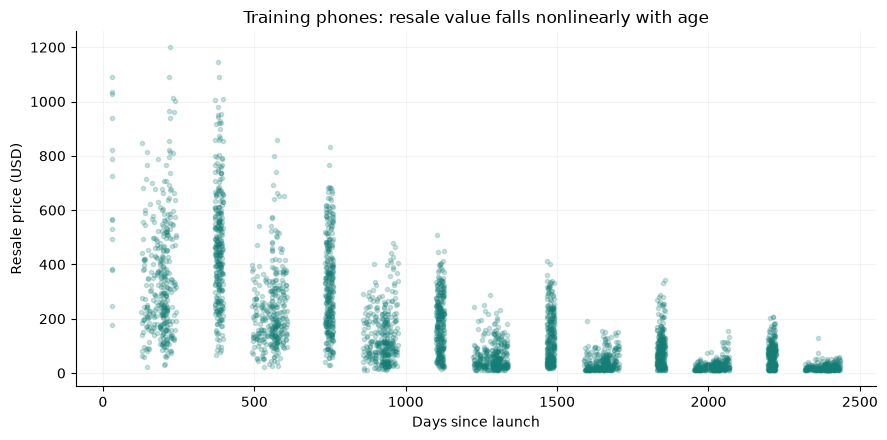

,training_median_resale_usd
phone_age,
0,312.000
1,305.000
2,187.000
3,80.000
4,47.000
5,31.000
6,25.000


In [4]:
fig, ax = plt.subplots()
ax.scatter(train.days_since_launch, train.resale_price, s=9, alpha=0.22, color='#147D75')
ax.set(xlabel='Days since launch', ylabel='Resale price (USD)',
       title='Training phones: resale value falls nonlinearly with age')
fig.tight_layout()
fig.savefig('evidence/phone-price-over-time.png', dpi=150)
plt.show()
age_resale = train.groupby('phone_age').resale_price.median()
display(age_resale.rename('training_median_resale_usd').to_frame())

**Answer — Price over time.** The scatter shows a steep decline in resale value followed by a flatter low-price region, with substantial spread at similar ages. Training median resale prices fall from $312.00 for age-0 phones to $80.00 at age 3 and $25.00 at age 6. A single straight line misses this curvature and the differing price levels of phone types.

### One shared preprocessor

Numerical features receive training-fitted median imputation and z-score scaling.
Categorical features receive most-frequent imputation and full one-hot encoding, with
unknown categories ignored. Keeping every category lets us compare category weights by
subtraction as requested. Individual dummy coefficients depend on the redundant coding;
within-column contrasts are the meaningful comparisons. Each model gets an unfitted clone
of this same preprocessor. Cross-validation refits preprocessing inside each training fold.

In [5]:
num_features = X_train.select_dtypes(include='number').columns.tolist()
cat_features = [c for c in X_train.columns if c not in num_features]
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features),
])
print('Numerical:', num_features)
print('Categorical:', cat_features)

Numerical: ['release_year', 'days_since_launch', 'launch_price', 'storage_gb', 'battery_health']
Categorical: ['brand', 'tier', 'screen_condition', 'has_box', 'repaired_before']


## Part 2B — Train and compare

### Step 1 — Model-free baseline

Use the **training mean**, without consulting test prices. Final scoring is deferred to
Step 5 so all models are evaluated after tuning is finished.

In [6]:
baseline_value = float(y_train.mean())
print(f'Baseline prediction for every phone: ${baseline_value:,.3f}')

Baseline prediction for every phone: $165.043


### Step 2 — Linear regression

In [7]:
lr_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('lin_reg', LinearRegression()),
])
lr_pipeline.fit(X_train, y_train)
print('Linear regression fitted on', len(X_train), 'training phones; no grid search.')

Linear regression fitted on 4000 training phones; no grid search.


### Step 3 — SGD: the eight required parameter combinations, five folds

In [8]:
sgd_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('sgd', SGDRegressor(random_state=409)),
])
sgd_grid = {
    'sgd__max_iter': [10000, 100000],
    'sgd__tol': [1e-5, 1e-3],
    'sgd__eta0': [0.01, 0.1],
}
sgd_search = GridSearchCV(sgd_pipeline, sgd_grid, cv=5,
    scoring='neg_root_mean_squared_error', n_jobs=2, error_score='raise')
sgd_search.fit(X_train, y_train)
sgd_best = sgd_search.best_estimator_
print('Best SGD parameters:', sgd_search.best_params_)
print('Best training CV RMSE:', -sgd_search.best_score_)
display(pd.DataFrame(sgd_search.cv_results_)[['params', 'mean_test_score', 'rank_test_score']])

Best SGD parameters: {'sgd__eta0': 0.01, 'sgd__max_iter': 10000, 'sgd__tol': 1e-05}
Best training CV RMSE: 97.88047458557473


,params,mean_test_score,rank_test_score
0,"{'sgd__eta0': 0.01, 'sgd__max_iter': 10000, 's...",-97.880,1
1,"{'sgd__eta0': 0.01, 'sgd__max_iter': 10000, 's...",-97.880,1
2,"{'sgd__eta0': 0.01, 'sgd__max_iter': 100000, '...",-97.880,1
3,"{'sgd__eta0': 0.01, 'sgd__max_iter': 100000, '...",-97.880,1
4,"{'sgd__eta0': 0.1, 'sgd__max_iter': 10000, 'sg...",-99.005,5
5,"{'sgd__eta0': 0.1, 'sgd__max_iter': 10000, 'sg...",-99.005,5
6,"{'sgd__eta0': 0.1, 'sgd__max_iter': 100000, 's...",-99.005,5
7,"{'sgd__eta0': 0.1, 'sgd__max_iter': 100000, 's...",-99.005,5


### Step 4 — Random forest: the four required parameter combinations, five folds

In [9]:
rf_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('forest', RandomForestRegressor(random_state=409)),
])
rf_grid = {
    'forest__n_estimators': [100, 150],
    'forest__max_depth': [5, 10],
}
rf_search = GridSearchCV(rf_pipeline, rf_grid, cv=5,
    scoring='neg_root_mean_squared_error', n_jobs=2, error_score='raise')
rf_search.fit(X_train, y_train)
rf_best = rf_search.best_estimator_
print('Best random forest parameters:', rf_search.best_params_)
print('Best training CV RMSE:', -rf_search.best_score_)
display(pd.DataFrame(rf_search.cv_results_)[['params', 'mean_test_score', 'rank_test_score']])

Best random forest parameters: {'forest__max_depth': 10, 'forest__n_estimators': 150}
Best training CV RMSE: 58.467616793262366


,params,mean_test_score,rank_test_score
0,"{'forest__max_depth': 5, 'forest__n_estimators...",-64.869,3
1,"{'forest__max_depth': 5, 'forest__n_estimators...",-64.905,4
2,"{'forest__max_depth': 10, 'forest__n_estimator...",-58.661,2
3,"{'forest__max_depth': 10, 'forest__n_estimator...",-58.468,1


### Step 5 — One final predictive scorecard on the locked test set

Both searches are now finished. No model, feature or parameter is changed after this point.

In [10]:
predictions = {
    'Baseline': np.full(len(X_test), baseline_value),
    'Linear regression': lr_pipeline.predict(X_test),
    'SGD': sgd_best.predict(X_test),
    'Random forest': rf_best.predict(X_test),
}
scores = pd.DataFrame({name: {
    'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
    'MAE': mean_absolute_error(y_test, pred),
    'R_squared': r2_score(y_test, pred),
} for name, pred in predictions.items()}).T
y_pred_lr = predictions['Linear regression']
y_pred_rf = predictions['Random forest']
display(scores)
improvements = pd.DataFrame({
    'RMSE_reduction_USD': scores.loc['Baseline', 'RMSE'] - scores.RMSE,
    'MAE_reduction_USD': scores.loc['Baseline', 'MAE'] - scores.MAE,
    'R_squared_increase': scores.R_squared - scores.loc['Baseline', 'R_squared'],
}).drop(index='Baseline')
display(improvements)
scores.to_csv('evidence/phone_model_scores.csv')

,RMSE,MAE,R_squared
Baseline,181.806,137.530,-0.000
Linear regression,98.007,71.345,0.709
SGD,97.910,71.613,0.710
Random forest,55.195,33.211,0.908


,RMSE_reduction_USD,MAE_reduction_USD,R_squared_increase
Linear regression,83.799,66.185,0.709
SGD,83.896,65.917,0.710
Random forest,126.612,104.319,0.908


**Answer — Which model is best?** The random forest wins all three scores: RMSE **$55.19**, MAE **$33.21**, and R² **0.9078**. The baseline has RMSE $181.81, MAE $137.53, and R² -0.000009. Improvements over the baseline are: Linear regression: RMSE lower by $83.80, MAE lower by $66.18, and R² higher by 0.7094; SGD: RMSE lower by $83.90, MAE lower by $65.92, and R² higher by 0.7100; Random forest: RMSE lower by $126.61, MAE lower by $104.32, and R² higher by 0.9078. Higher R² is better; lower RMSE and MAE are better.

**Answer — Same model, two algorithms.** Their results are close: linear regression has RMSE $98.01 and SGD $97.91, a difference of only $0.10. Their R² values are 0.7094 and 0.7100. Both fit additive linear predictions on exactly the same transformed features; one solves least squares directly and the other updates weights iteratively. Exact equality is not expected because SGD has finite stopping tolerance and its specified default also includes a small L2 penalty, unlike the unregularized least-squares model. The selected SGD settings are `eta0=0.01`, `max_iter=10000`, `tol=1e-5`.

### Question 5 — Why the forest wins: count impossible linear predictions

In [11]:
negative_linear_count = int((y_pred_lr < 0).sum())
linear_price_by_age = pd.DataFrame({
    'phone_age': 2025 - X_test.release_year,
    'actual': y_test, 'linear_prediction': y_pred_lr,
    'negative_prediction': y_pred_lr < 0,
}).groupby('phone_age').agg(
    phones=('actual', 'size'), mean_actual=('actual', 'mean'),
    mean_prediction=('linear_prediction', 'mean'), negative_predictions=('negative_prediction', 'sum')
)
print('Negative linear regression predictions:', negative_linear_count, 'out of', len(X_test))
display(linear_price_by_age)

Negative linear regression predictions: 166 out of 1000


,phones,mean_actual,mean_prediction,negative_predictions
phone_age,,,,
0,87,366.195,324.315,0
1,137,351.460,318.325,0
2,175,234.869,245.426,2
3,161,108.745,160.088,8
4,156,74.737,103.587,27
5,128,60.461,46.848,45
6,156,41.603,-17.239,84


**Answer — Why the forest wins.** Linear regression predicts **166 negative resale prices out of 1,000 test phones**, which is economically impossible here. The training scatter shows a curved depreciation pattern; the additive straight-line model cannot follow both the steep early decline and the low-price floor. The forest can split on age, original price and condition and fit different price levels in different regions. Its predictions are averages of positive training prices and therefore cannot be negative in this dataset. Its RMSE is $42.81 lower than the linear model's; this is evidence for this dataset, not a guarantee that forests always win.

## Part 2C — Interpret the models

### Step 1 — Linear weights and requested category contrasts

Numerical coefficients below are dollars per one **training standard deviation**.
Category contrasts are dollars relative to another category of the same input, holding
the other model inputs fixed. They describe the fitted prediction, not causal effects.

In [12]:
weights = pd.Series(lr_pipeline['lin_reg'].coef_,
    index=lr_pipeline['preprocessor'].get_feature_names_out())
print(weights.round(0).to_string())
screen_difference = float(weights['cat__screen_condition_cracked'] - weights['cat__screen_condition_perfect'])
apple_honor_difference = float(weights['cat__brand_Apple'] - weights['cat__brand_Honor'])
repair_difference = float(weights['cat__repaired_before_yes'] - weights['cat__repaired_before_no'])
contrasts = pd.Series({
    'Cracked minus perfect screen': screen_difference,
    'Apple minus Honor': apple_honor_difference,
    'Previously repaired minus not repaired': repair_difference,
}, name='Predicted price difference (USD)')
display(contrasts.to_frame())

num__release_year                  -38.000
num__days_since_launch            -125.000
num__launch_price                   64.000
num__storage_gb                      5.000
num__battery_health                 37.000
cat__brand_Apple                    44.000
cat__brand_Honor                   -23.000
cat__brand_Huawei                   -5.000
cat__brand_OPPO                    -14.000
cat__brand_Samsung                  20.000
cat__brand_Xiaomi                  -11.000
cat__brand_vivo                    -10.000
cat__tier_budget                   -10.000
cat__tier_flagship                  13.000
cat__tier_mid-range                 -3.000
cat__screen_condition_cracked      -46.000
cat__screen_condition_perfect       28.000
cat__screen_condition_scratched     18.000
cat__has_box_no                     -4.000
cat__has_box_yes                     4.000
cat__repaired_before_no             11.000
cat__repaired_before_yes           -11.000


,Predicted price difference (USD)
Cracked minus perfect screen,-73.811
Apple minus Honor,67.794
Previously repaired minus not repaired,-21.836


**Answer — What the linear weights say.** Subtracting the requested category coefficients gives:

- A cracked screen changes the predicted price by **$-73.81** compared with a perfect screen: about a $73.81 deduction.
- An Apple phone is predicted to be **$67.79 more** than an otherwise identical Honor.
- Having been repaired before changes the prediction by **$-21.84**, about a $21.84 deduction.

These are conditional comparisons from the fitted simulated-data model; they are not real-world causal estimates.

**Answer — One number for every phone.** The model deducts the same $73.81 for a cracked screen from a $150 budget phone and a $900 flagship, equivalent to 49.2% and 8.2% of those prices. A universal dollar deduction is restrictive because screen damage can matter differently by original price, tier and age. A random forest can first split on these variables and then learn different screen-condition effects in the resulting groups. It can represent interactions; whether a particular interaction is present must still be checked against data.

### Step 2 — Test-set permutation importance

Run the requested `scoring='neg_root_mean_squared_error'`, `n_repeats=10`,
`random_state=409` analysis on each **complete pipeline**, so the original input
features are permuted. Positive values are increases in RMSE (USD) after shuffling.
This is post-selection interpretation, not another model-selection exercise.

In [13]:
importances = {}
for name, model in [('Linear regression', lr_pipeline), ('Random forest', rf_best)]:
    result = permutation_importance(model, X_test, y_test,
        scoring='neg_root_mean_squared_error', n_repeats=10, random_state=409, n_jobs=2)
    table = pd.DataFrame({'RMSE_increase_USD': result.importances_mean,
        'repeat_std_USD': result.importances_std}, index=X_test.columns)
    table = table.sort_values('RMSE_increase_USD', ascending=False)
    importances[name] = table
    print(name, '— five most important original features')
    display(table.head(5))
    table.to_csv('evidence/importance-' + name.lower().replace(' ', '-') + '.csv')

Linear regression — five most important original features


,RMSE_increase_USD,repeat_std_USD
days_since_launch,101.601,3.162
launch_price,35.957,1.697
release_year,14.513,1.104
battery_health,12.115,0.944
brand,6.501,0.895


Random forest — five most important original features


,RMSE_increase_USD,repeat_std_USD
days_since_launch,143.037,3.781
launch_price,103.241,4.881
screen_condition,11.843,0.919
brand,10.138,1.557
battery_health,6.941,0.792


**Answer — What drives the price?** The linear model's top five features are `days_since_launch` (+$101.60), `launch_price` (+$35.96), `release_year` (+$14.51), `battery_health` (+$12.12), `brand` (+$6.50). The forest's top five are `days_since_launch` (+$143.04), `launch_price` (+$103.24), `screen_condition` (+$11.84), `brand` (+$10.14), `battery_health` (+$6.94).

Both rank days since launch first and original launch price second, and both include battery health and brand in their top five. The linear model also relies on release year, while the forest places screen condition in its top five and obtains almost no additional importance from release year. Release year and days since launch overlap in the age information they carry, so individual permutation rankings are affected by redundancy; they should not be read as causal importance. The printed standard deviations describe variation across shuffles, not confidence intervals for production performance.

## Part 2D — Turn predictions into the trade-in decision

The offer equals `offer_rate * predicted price`. A seller accepts when the offer is
at least 75% of actual resale value. Accepted-phone profit is `actual - offer`;
rejected phones contribute zero. No transaction, repair, shipping or holding costs
are included in this assignment's simplified profit definition.

In [14]:
def trade_in_profit(predicted, actual, offer_rate):
    """Offer offer_rate x predicted price; sellers accept at >=75% of actual."""
    offer = offer_rate * predicted
    accepted = offer >= 0.75 * actual
    profit = (actual - offer)[accepted]
    return accepted.sum(), profit.sum()

actual = y_test.to_numpy()
offer_rates = np.round(np.arange(0.60, 0.901, 0.05), 2)
rows = []
for rate in offer_rates:
    row = {'offer_rate': rate}
    for name in ['Baseline', 'Linear regression', 'Random forest']:
        count, profit = trade_in_profit(predictions[name], actual, rate)
        row[name + ' bought'] = int(count)
        row[name + ' profit_USD'] = float(profit)
    rows.append(row)
profit_table = pd.DataFrame(rows).set_index('offer_rate')
display(profit_table)
profit_table.to_csv('evidence/phone_offer_rate_profit.csv')

,Baseline bought,Baseline profit_USD,Linear regression bought,Linear regression profit_USD,Random forest bought,Random forest profit_USD
offer_rate,,,,,,
0.600,581,"-29,658.077",430,"-2,353.567",266,"2,898.772"
0.650,602,"-33,804.424",471,"-4,128.194",361,"4,899.690"
0.700,624,"-38,031.892",525,"-5,564.413",448,"5,301.711"
0.750,648,"-42,296.020",580,"-6,876.718",568,"5,700.761"
0.800,666,"-46,938.044",619,"-9,730.111",656,"5,053.833"
0.850,690,"-51,444.866",649,"-13,549.702",737,"4,023.427"
0.900,708,"-56,329.559",672,"-18,242.533",799,"1,151.504"


### Step 2 — Linear regression at 75%: include zeros for rejected phones

In [15]:
linear_offers = 0.75 * y_pred_lr
linear_accepted = linear_offers >= 0.75 * actual
per_phone_profit = np.where(linear_accepted, actual - linear_offers, 0.0)
age_profit = pd.DataFrame({
    'phone_age': (2025 - X_test.release_year).to_numpy(), 'profit': per_phone_profit,
    'accepted': linear_accepted, 'actual': actual, 'prediction': y_pred_lr,
}).groupby('phone_age').agg(
    phones=('profit', 'size'), bought=('accepted', 'sum'),
    total_profit_USD=('profit', 'sum'), mean_actual_USD=('actual', 'mean'),
    mean_prediction_USD=('prediction', 'mean'),
)
assert np.isclose(age_profit.total_profit_USD.sum(), profit_table.loc[0.75, 'Linear regression profit_USD'])
display(age_profit)
age_profit.to_csv('evidence/phone_linear_profit_by_age.csv')

,phones,bought,total_profit_USD,mean_actual_USD,mean_prediction_USD
phone_age,,,,,
0,87,38,-793.376,366.195,324.315
1,137,78,"1,269.772",351.460,318.325
2,175,121,-597.799,234.869,245.426
3,161,138,"-3,082.320",108.745,160.088
4,156,114,"-2,312.034",74.737,103.587
5,128,58,-985.383,60.461,46.848
6,156,33,-375.577,41.603,-17.239


**Answer — R-squared is not profit.** Linear regression has R² **0.7094**, yet at a 75% offer rate it loses **$6,876.72**. Age 3 contributes $-3,082.32, age 4 $-2,312.03, and age 5 $-985.38; together these are $-6,379.74. At age 3, mean actual resale is $108.75 while the mean prediction is $160.09; at age 4 the corresponding amounts are $74.74 and $103.59.

Overpriced offers are especially likely to be accepted, so overall predictive fit does not protect the platform against losses on the selected purchases. The age-1 group earns $1,269.77, which is insufficient to offset the other groups' losses. All 1,000 phones are included in the age table and rejected offers contribute zero, exactly as requested.

### Evidence for the offer-rate and adverse-selection questions

In [16]:
best_rf_rate = float(profit_table['Random forest profit_USD'].idxmax())
best_rf_profit = float(profit_table.loc[best_rf_rate, 'Random forest profit_USD'])
best_rf_bought = int(profit_table.loc[best_rf_rate, 'Random forest bought'])
print(f'Best random forest offer rate: {best_rf_rate:.2f}; bought: {best_rf_bought}; profit: ${best_rf_profit:,.2f}')
baseline_selection = []
for rate in offer_rates:
    offered = rate * baseline_value
    accepted = offered >= 0.75 * actual
    baseline_selection.append({
        'offer_rate': rate, 'same_offer_USD': offered, 'bought': int(accepted.sum()),
        'accepted_mean_resale_USD': float(actual[accepted].mean()),
        'share_accepted_at_loss_pct': float((actual[accepted] < offered).mean() * 100),
    })
baseline_selection = pd.DataFrame(baseline_selection).set_index('offer_rate')
display(baseline_selection)

Best random forest offer rate: 0.75; bought: 568; profit: $5,700.76


,same_offer_USD,bought,accepted_mean_resale_USD,share_accepted_at_loss_pct
offer_rate,,,,
0.600,99.026,581,47.979,87.091
0.650,107.278,602,51.125,88.538
0.700,115.530,624,54.582,87.660
0.750,123.782,648,58.511,87.037
0.800,132.035,666,61.557,87.237
0.850,140.287,690,65.729,86.087
0.900,148.539,708,68.977,86.441


**Answer — The best offer.** Among the seven required rates, the forest's best rate is **75%**, buying **568 phones** and earning **$5,700.76**. At 60%, it buys only 266 phones and earns $2,898.77: many valuable sellers reject low offers. At 90%, it buys 799 phones but earns only $1,151.50: paying more compresses margins and increases overpayment exposure. The 75% rate balances these forces on this particular test sample. It is the best tested rate, not a proven continuous or future optimum; production policy selection needs a separate validation period.

**Answer — The baseline and adverse selection.** The baseline predicts the training mean, $165.04, for every phone. At a 75% rate, it therefore offers the same **$123.78** to everyone. Sellers accept if actual value is at most `offer / 0.75`, so cheaper phones are disproportionately selected and many high-value phones leave. The 648 accepted phones have an average actual resale value of only **$58.51**; 87.04% are bought above their actual resale value. This produces $-42,296.02 total profit.

The same pattern holds at all seven rates in the displayed diagnostic table: accepted phones' mean resale value is below the common offer, so the baseline loses money at every tested rate. This explains the loss in the supplied data. A constant offer does not mathematically guarantee a loss for every possible price distribution or on every accepted individual phone.

## Part 2E — Advice to the platform manager

Four to six sentences, using dollar evidence and business language.

I recommend the pricing approach that adjusts each phone's valuation to its age, original price and condition, with an offer set at **75% of its estimated resale value**. In this simulated batch of 1,000 seller submissions, it bought **568 phones** and earned **$5,700.76 before operating costs**, which is the planning figure I would use only for a comparable batch. The simpler straight-line pricing approach lost $6,876.72 at the same offer percentage. Actual results may be worse because shipping, inspection, repairs, holding costs and changes in seller behavior are not included. Before committing a large budget, verify the offer percentage on a separate set of transactions and run a small pilot with spending and overpayment limits.

## Reproducibility and evidence export

This cell exports the numbers used in the answers. It does not fit, tune or rescore a
model. Re-run from the top with the supplied CSV and pinned project environment.

In [17]:
summary = {
    'data_sha256': hashlib.sha256(Path('phone_trade_in.csv').read_bytes()).hexdigest(),
    'python': platform.python_version(), 'sklearn': sklearn.__version__,
    'training_rows': len(X_train), 'test_rows': len(X_test),
    'missing_pct_by_brand': missing_by_brand.to_dict(),
    'battery_median_by_brand': battery_by_brand.to_dict(),
    'battery_median_by_age': battery_by_age['median'].to_dict(),
    'global_battery_median': global_battery_median,
    'resale_median_by_age': age_resale.to_dict(),
    'training_mean_price': baseline_value,
    'sgd_best_parameters': sgd_search.best_params_, 'rf_best_parameters': rf_search.best_params_,
    'scores': scores.to_dict(orient='index'),
    'improvements': improvements.to_dict(orient='index'),
    'negative_linear_predictions': negative_linear_count,
    'linear_price_by_age': linear_price_by_age.to_dict(orient='index'),
    'contrasts': contrasts.to_dict(),
    'importance': {name: table.to_dict(orient='index') for name, table in importances.items()},
    'profit_table': profit_table.to_dict(orient='index'),
    'baseline_selection': baseline_selection.to_dict(orient='index'),
    'age_profit': age_profit.to_dict(orient='index'),
    'best_rf_rate': best_rf_rate, 'best_rf_profit': best_rf_profit,
    'best_rf_bought': best_rf_bought,
}
Path('evidence/phone_results.json').write_text(json.dumps(summary, indent=2) + '\n')
prediction_evidence = pd.DataFrame({'phone_id': df.loc[X_test.index, 'phone_id'],
    'actual_USD': actual, **{name: pred for name, pred in predictions.items()}})
prediction_evidence.to_csv('evidence/phone_test_predictions.csv', index=False)
print('Evidence exported. All question answers refer to the outputs immediately above them.')

Evidence exported. All question answers refer to the outputs immediately above them.
